## PlantTraits



**Reference solution, for instructors only. Do not share with students.**

The answers below are examples: the questions are open-ended, and other well-justified choices are valid.

The whole notebook ran in about 10 minutes on an RTX 5090, with 4 processes loading the images as in the student notebook. Sections 3 and 4 train neural networks and need a GPU. Their DINOv2 option needs the shared embeddings in `data/embeddings/`, computed with `embeddings.py`. This run used PyTorch 2.7.1, because the course version (2.6.0) does not support the RTX 5090. Scores come from a single run, so small differences between models should not be over-interpreted.

### Project

This end of course project present you with a real-life application of Machine Learning on plant science data. 

The goal of this project is to predict plant trait characteristics from climate and soil features, satellite features and photographs. The task and data was first published for the CVPR 2024 FGVC11 (Fine-Grained Visual Categorization) Workshop and is hosted on Kaggle. 

This notebook guides you through a few steps and different design to solve the task. The project is kept quite open-ended and meant for you to explore solutions. Feel free to spend more time and effort on the portion that are most interesting to you. We do not expect nor aim for your solutions to compete with the Kaggle competition benchmark (optimizing hyperparameters is not within the scope of the lab). 

The notebook includes several **questions** text cell. Please fill those in your own words. The question are made to assess your understanding. They are also open-ended and do not have single right answer. 

If you have data and a project you'd prefer to work on, you are encouraged to do so. The only requirement is for you to work on novel Machine Learning methods presented during the course. Make sure to present your project to us so that we can make sure the project is a fit and advise you on the scope and direction to take. 

For submission of this final project required to validate the credits for the course, please share with the TAs your work before December 4th (extensions may be awarded if justified). Prefered format is a private github repository shared with the TAs (TGazel). Zip files via emails are also accepted. 

### Data source

This project uses the data of the [PlantTraits2024 Kaggle competition](https://www.kaggle.com/competitions/planttraits2024), which combines:
- plant photographs shared by citizen scientists on [iNaturalist](https://www.inaturalist.org/)
- plant trait values from the [TRY plant trait database](https://www.try-db.org/)
- environmental data read from global maps at the location of each photograph

Predicting plant traits by combining iNaturalist photographs with TRY data is described in this paper:

> Schiller, C., Schmidtlein, S., Boonman, C., Moreno-Martínez, A., Kattenborn, T. (2021). [Deep learning and citizen science enable automated plant trait predictions from photographs](https://www.nature.com/articles/s41598-021-95616-0). *Scientific Reports*, 11, 16395.

### Task

The task for this project is to **predict six plant traits from a photograph of a plant and from environmental data at the location where the photograph was taken**.

## Dataset

The dataset contains 55,489 samples, one per photograph.

**Targets:** the six traits to predict.

| Target column | Trait | Unit |
|---|---|---|
| `X4_mean` | Stem specific density (wood density) | g/cm³ |
| `X11_mean` | Specific leaf area (leaf area per leaf dry mass) | mm²/mg |
| `X18_mean` | Plant height | m |
| `X26_mean` | Seed dry mass | mg |
| `X50_mean` | Leaf nitrogen content per leaf area | g/m² |
| `X3112_mean` | Leaf area | mm² |

**Inputs:** a photograph of 512x512 pixels, and 163 environmental variables.

| Input columns | Number | Content |
|---|---|---|
| `WORLDCLIM_*` | 6 | Climate: temperature and precipitation |
| `SOIL_*` | 61 | Soil properties (for example sand, clay, pH, nitrogen) at different depths |
| `MODIS_*` | 60 | Optical satellite data: surface reflectance, 5 spectral bands x 12 months |
| `VOD_*` | 36 | Radar satellite data: vegetation optical depth, 3 frequency bands x 12 months |

The table also contains the columns `X4_sd`, ..., `X3112_sd`: the standard deviation of each trait. They describe the targets and would not be known for a new photograph, so they cannot be used as model inputs.

## Data download

The dataset is hosted on Kaggle. The download is 3.2 GB, and you need about 7 GB of free disk space to download and unzip it.

**1. Accept the competition rules.** Create a free [Kaggle](https://www.kaggle.com/) account if you do not have one, then open the [competition rules](https://www.kaggle.com/competitions/planttraits2024/rules) and accept them. Without this step, the download is refused.

**2. Download the data**, with one of these two options:

- **Option A, zip download:** on the [Data tab](https://www.kaggle.com/competitions/planttraits2024/data) of the competition, download all the files as `planttraits2024.zip`, and move this file to the folder `5-PlantTraits/data/planttraits2024`.
- **Option B, API key:** in your [Kaggle settings](https://www.kaggle.com/settings), create a new API token and copy it. Keep this token private. Then, in a terminal with the course environment activated, run from the folder `5-PlantTraits`:

```bash
pip install kaggle six
export KAGGLE_API_TOKEN=your_token    # on Windows (Anaconda Prompt): set KAGGLE_API_TOKEN=your_token
kaggle competitions download -c planttraits2024 -p data/planttraits2024
```

**3. Unzip** `planttraits2024.zip` in the folder `5-PlantTraits/data/planttraits2024`, to obtain the structure below. You can then delete the zip file, as well as the files `test.csv`, `sample_submission.csv` and the folder `test_images/`: the test set of the competition has no public target values, so we do not use it.

```
5-PlantTraits/
├── 5-PlantTraits.ipynb
├── utils.py
└── data/
    └── planttraits2024/
        ├── train.csv
        ├── target_name_meta.tsv
        └── train_images/
```

**Note:** `train.csv` and `train_images/` are the names given by Kaggle. In this project, they contain the **whole dataset**, which you will split yourself.

## Data preparation

Functions to load and display data are in the file `utils.py`, next to this notebook.

In [1]:
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader
from torchvision import models, transforms

from utils import PlantDataset, load_data, load_embeddings, load_image, show_sample, show_samples

torch.manual_seed(42)  # for reproducibility
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


In [2]:
data_df, target_cols, feature_cols = load_data()

image = load_image(data_df["id"].iloc[0])
print(f"Image size: {image.size}")

55489 samples, 163 input columns, 6 targets
0 samples without an image
Image size: (512, 512)


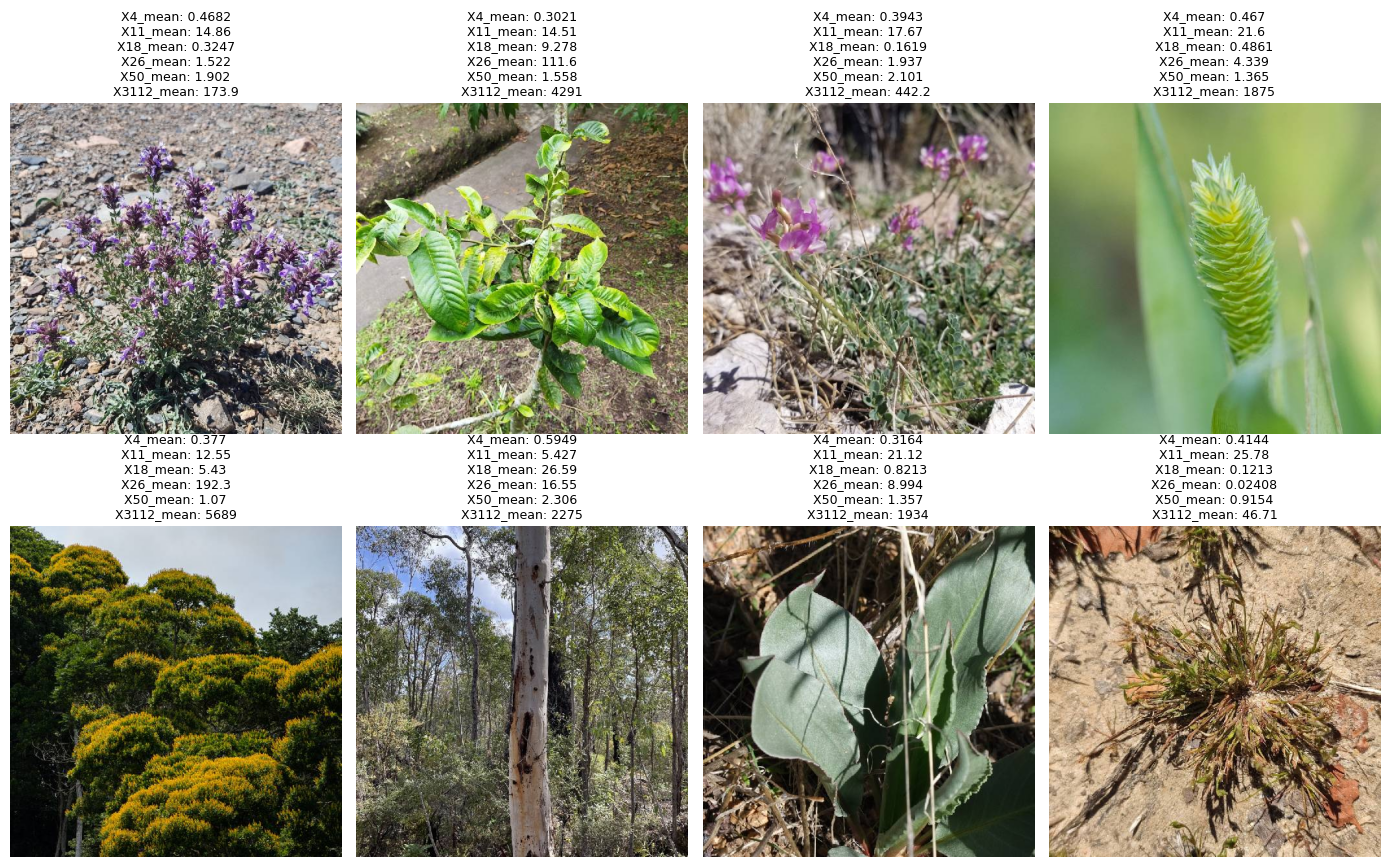

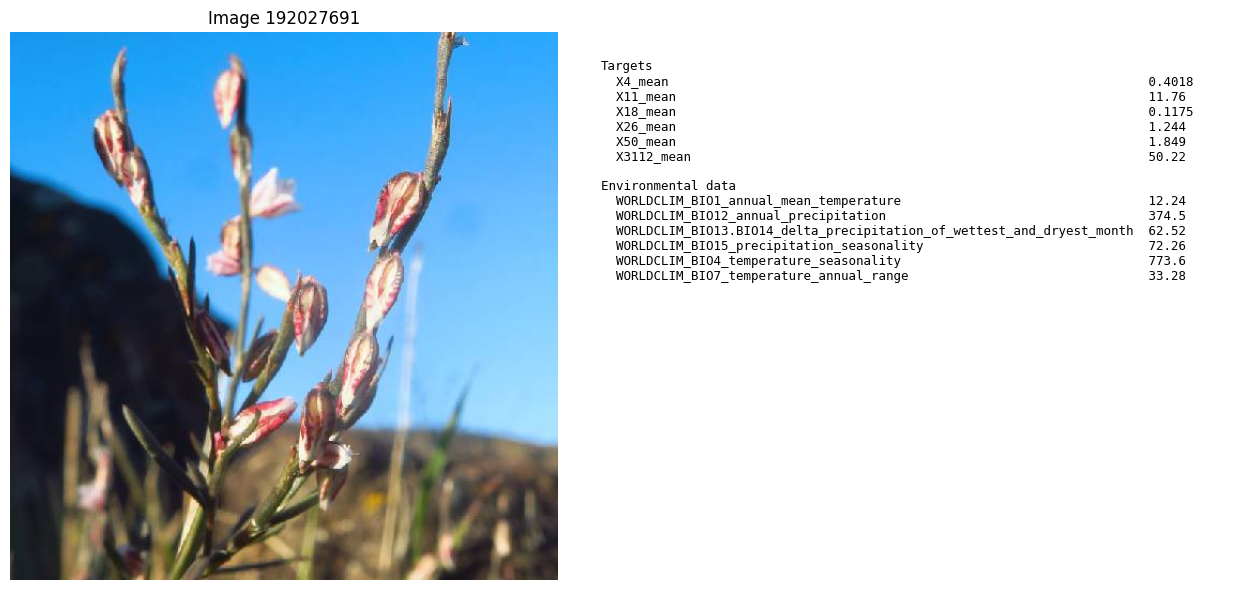

In [3]:
# Some images and their target values
show_samples(data_df, random_state=42)

# One image, with its target values and climate data
show_sample(data_df.iloc[0])

### Splitting the data

To evaluate the models on samples they have not seen, `data_df` is split between a training set, a validation set and a test set. The validation set is used to compare models and settings, for example to choose the best training epoch in section 3, and the test set only to evaluate the final models.

The positions (row numbers in `data_df`) of the samples of each set are stored in `train_idx`, `val_idx` and `test_idx`.

In [4]:
# Photographs with identical target values belong to the same species
species = data_df.groupby(target_cols).ngroup().to_numpy()

# 20% of the species for testing, 10% for validation and 70% for training
outer_split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_val_idx, test_idx = next(outer_split.split(data_df, groups=species))
inner_split = GroupShuffleSplit(n_splits=1, test_size=0.125, random_state=42)
train_pos, val_pos = next(inner_split.split(train_val_idx, groups=species[train_val_idx]))
train_idx, val_idx = train_val_idx[train_pos], train_val_idx[val_pos]

for name, idx in [("Training", train_idx), ("Validation", val_idx), ("Test", test_idx)]:
    print(f"{name}: {len(idx)} samples, {len(set(species[idx]))} species")

Training: 38889 samples, 13859 species
Validation: 5485 samples, 1980 species
Test: 11115 samples, 3960 species


In [5]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

#### Exploring the targets

In [6]:
print(f"Missing input values: {data_df[feature_cols].isna().sum().sum()}")
print(f"Missing target values: {data_df[target_cols].isna().sum().sum()}")
print(f"Non-positive target values: {(data_df[target_cols] <= 0).sum().to_dict()}")

data_df[target_cols].describe(percentiles=[0.01, 0.5, 0.99])

Missing input values: 0
Missing target values: 0
Non-positive target values: {'X4_mean': 155, 'X11_mean': 0, 'X18_mean': 0, 'X26_mean': 0, 'X50_mean': 0, 'X3112_mean': 0}


,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean
count,55489.000000,5.548900e+04,5.548900e+04,5.548900e+04,55489.000000,5.548900e+04
mean,0.522575,1.325267e+02,1.969902e+04,3.459399e+03,13.528574,3.975552e+05
std,0.174853,1.278220e+04,2.309747e+06,2.471919e+05,1356.480785,9.152463e+07
min,-2.431157,6.780000e-05,2.330000e-08,5.500000e-07,0.000097,7.690000e-08
1%,0.227442,3.074351e+00,4.120896e-02,1.077357e-02,0.492031,1.127723e+01
50%,0.509009,1.511232e+01,7.156651e-01,2.519985e+00,1.480060,7.244318e+02
99%,0.920609,5.082798e+01,2.852370e+01,1.395933e+03,4.464096,2.453972e+04
max,4.475172,1.504254e+06,2.720494e+08,3.106555e+07,159759.897700,2.155911e+10


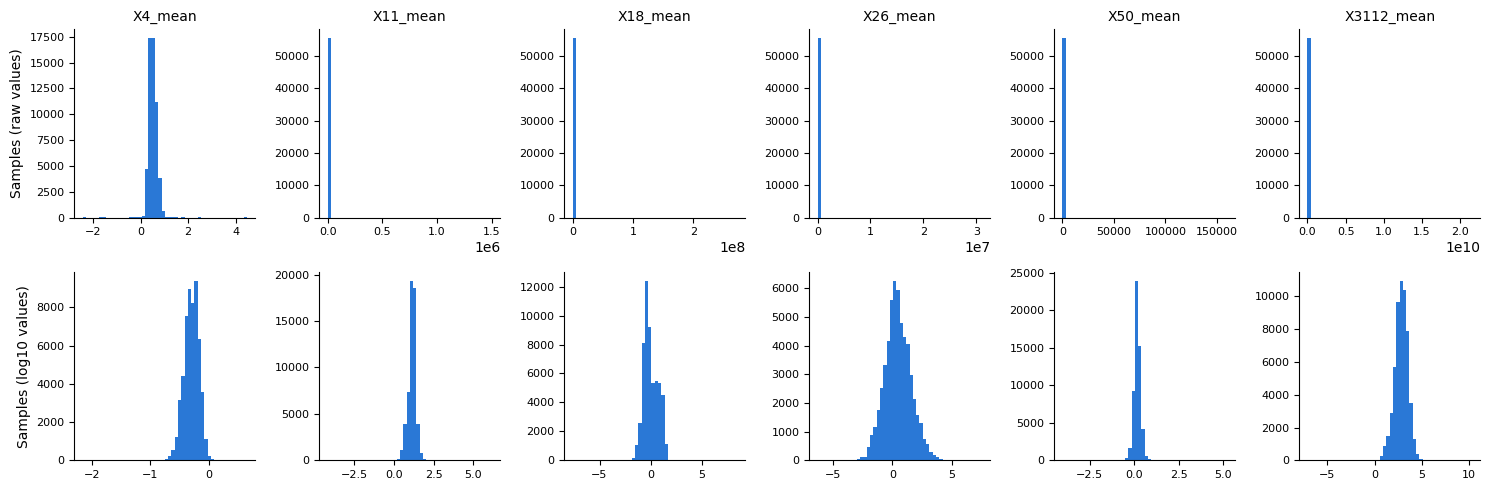

In [7]:
# Distribution of the targets, before and after a log10 transform
log_values = np.log10(data_df[target_cols].where(data_df[target_cols] > 0))

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for column, col in enumerate(target_cols):
    axes[0, column].hist(data_df[col], bins=50, color="#2a78d6")
    axes[0, column].set_title(col, fontsize=10)
    axes[1, column].hist(log_values[col].dropna(), bins=50, color="#2a78d6")
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8)
axes[0, 0].set_ylabel("Samples (raw values)")
axes[1, 0].set_ylabel("Samples (log10 values)")
plt.tight_layout()
plt.show()

#### Cleaning the targets

In [8]:
# Log10 of the positive values, standardized with statistics from the training set only
log_targets = log_values.to_numpy()
target_mean = np.nanmean(log_targets[train_idx], axis=0)
target_std = np.nanstd(log_targets[train_idx], axis=0)
y = (log_targets - target_mean) / target_std

# Remove the non-positive values, and the outliers beyond 3 standard deviations
keep = (np.abs(y) <= 3).all(axis=1)
for name, idx in [("Training", train_idx), ("Validation", val_idx), ("Test", test_idx)]:
    print(f"{name}: {(~keep[idx]).sum()} samples removed, {keep[idx].sum()} remaining")
train_idx, val_idx, test_idx = train_idx[keep[train_idx]], val_idx[keep[val_idx]], test_idx[keep[test_idx]]

Training: 787 samples removed, 38102 remaining
Validation: 127 samples removed, 5358 remaining
Test: 270 samples removed, 10845 remaining


In [9]:
results, predictions = {}, {}


def evaluate(name, val_pred, test_pred, start_time):
    """Store the scores and predictions of a model, and show its results."""
    scores = r2_score(y[test_idx], test_pred, multioutput="raw_values")
    results[name] = {
        "val R²": r2_score(y[val_idx], val_pred),
        "test R²": scores.mean(),
        **dict(zip(target_cols, scores)),
        "test MAE (log10)": (np.abs(y[test_idx] - test_pred) * target_std).mean(),
        "minutes": (time.perf_counter() - start_time) / 60,
    }
    predictions[name] = (val_pred, test_pred)
    return pd.DataFrame([results[name]], index=[name]).round(3)

#### Questions
- Why is the data split this way, rather than with a random split of the samples?
- Which metrics can you use to assess performance for this task?
- Which data cleaning steps did you implement? Why?


**Answers**

- **Split:** whole species are held out, with 70% of the species for training, 10% for validation and 20% for testing. The targets are species-level values, so photographs with identical target values belong to the same species. With a random split of the samples, 85.6% of the test samples have their species in the training set, so a model can score well by recognizing species it has already seen, rather than by predicting traits for a new plant. The random forest reaches a mean R² of 0.286 with a random split, against 0.231 with held-out species: a random split overestimates how well a model works on new species. A random split can be defended if the goal is to predict known species only, but this has to be stated.
- **Metrics:** the R² of each trait and its mean over the six traits, which allows comparing traits with different units. The mean absolute error on the log10 scale is easier to interpret: the best model has an error of 0.224, which is a typical error of a factor of about 1.7. R² on the raw values is not reliable, because a few extreme values dominate it.
- **Data cleaning:** there are no missing values in the inputs or the targets. The `X*_sd` columns are not used as inputs. The targets are very skewed and contain impossible values, such as negative wood density (155 samples) or a plant height of 2.7 x 10⁸ m. We take the log10 of the targets, then remove non-positive values and outliers beyond 3 standard deviations, as in Schiller et al. (2021). This removes 1,184 of the 55,489 samples (2.1%). The statistics come from the training set only, to avoid leaking information from the test set. The targets are standardized so that each trait has the same weight during training.

## Models


### 1: climate and soil data

Start with a simple model using only the climate (`WORLDCLIM_*`) and soil (`SOIL_*`) columns.

In [10]:
start_time = time.perf_counter()
climate_soil_cols = [col for col in feature_cols if col.startswith(("WORLDCLIM", "SOIL"))]
X_climate_soil = data_df[climate_soil_cols].to_numpy()
print(f"{len(climate_soil_cols)} input columns")

baseline = make_pipeline(StandardScaler(), Ridge())
baseline.fit(X_climate_soil[train_idx], y[train_idx])
evaluate("1. Ridge, climate + soil", baseline.predict(X_climate_soil[val_idx]), baseline.predict(X_climate_soil[test_idx]), start_time)

67 input columns


,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"1. Ridge, climate + soil",0.176,0.19,0.152,0.186,0.311,0.17,0.093,0.226,0.34,0.001


#### Questions
- Explain your model choice. Explain how you prepared the input data and why.

**Answers**

- **Model:** a ridge regression, which is fast, easy to interpret, and robust to the strongly correlated soil columns (the same property at several depths). It gives a useful reference point: a mean R² of 0.190 on held-out species, from 0.093 for leaf nitrogen to 0.311 for plant height.
- **Input data:** the 67 climate and soil columns are standardized with the mean and standard deviation of the training set, because the ridge penalty depends on the scale of the inputs.

### 2: adding satellite imagery data

Train a machine learning model on all the environmental variables, including the satellite data (`MODIS_*` and `VOD_*`). 

You may train several model types and configurations.

In [11]:
X_tabular = data_df[feature_cols].to_numpy()
forest_settings = dict(n_estimators=100, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=SEED)

tabular_models = {
    "2. Ridge, all tabular": make_pipeline(StandardScaler(), Ridge()),
    "2. Random forest, all tabular": RandomForestRegressor(**forest_settings),
    "2. Gradient boosting, all tabular": MultiOutputRegressor(
        HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, early_stopping=False, random_state=SEED), n_jobs=6
    ),
}
for name, model in tabular_models.items():
    start_time = time.perf_counter()
    model.fit(X_tabular[train_idx], y[train_idx])
    evaluate(name, model.predict(X_tabular[val_idx]), model.predict(X_tabular[test_idx]), start_time)

pd.DataFrame(results).T.round(3)

,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"1. Ridge, climate + soil",0.176,0.190,0.152,0.186,0.311,0.170,0.093,0.226,0.340,0.001
"2. Ridge, all tabular",0.199,0.207,0.157,0.202,0.332,0.185,0.104,0.262,0.335,0.001
"2. Random forest, all tabular",0.215,0.231,0.163,0.251,0.375,0.217,0.105,0.272,0.326,0.092
"2. Gradient boosting, all tabular",0.230,0.241,0.178,0.255,0.374,0.232,0.122,0.286,0.324,0.065


#### Which data is the most important?

In [12]:
# Random forest trained on one data source at a time, scored on the validation set
source_scores = {}
for source in ["WORLDCLIM", "SOIL", "MODIS", "VOD"]:
    source_cols = [col for col in feature_cols if col.startswith(source)]
    X_source = data_df[source_cols].to_numpy()
    model = RandomForestRegressor(**forest_settings).fit(X_source[train_idx], y[train_idx])
    source_scores[source] = {"columns": len(source_cols), "val R²": r2_score(y[val_idx], model.predict(X_source[val_idx]))}

forest = tabular_models["2. Random forest, all tabular"]
importance = pd.Series(forest.feature_importances_, index=feature_cols).groupby(lambda col: col.split("_")[0]).sum()
source_table = pd.DataFrame(source_scores).T
source_table["share of forest importance"] = importance
source_table.round(3)

,columns,val R²,share of forest importance
WORLDCLIM,6.0,0.212,0.228
SOIL,61.0,0.201,0.373
MODIS,60.0,0.194,0.298
VOD,36.0,0.168,0.102


#### Pitfalls of a tabular model

In [13]:
# Samples with identical environmental inputs come from the same location
location = data_df[feature_cols].groupby(feature_cols).ngroup().to_numpy()
species_per_location = pd.Series(species).groupby(location).transform("nunique").to_numpy()
print(f"Distinct locations: {len(set(location))} for {len(data_df)} samples")
print(f"Test samples at a location with several species: {(species_per_location[test_idx] > 1).mean():.1%}")

# At one location, the model gives every plant the same prediction, whatever its species
test_pred = predictions["2. Random forest, all tabular"][1]
spread = pd.DataFrame(test_pred).groupby(location[test_idx]).std().max().max()
print(f"Largest difference between predictions at one location (standard deviation): {spread:.6f}")

Distinct locations: 36977 for 55489 samples
Test samples at a location with several species: 43.0%
Largest difference between predictions at one location (standard deviation): 0.000000


In [14]:
# Same random forest with a random split, where a species can be on both sides
kept_idx = np.flatnonzero(keep)
random_train, random_test = train_test_split(kept_idx, test_size=0.2, random_state=SEED)
random_forest = RandomForestRegressor(**forest_settings).fit(X_tabular[random_train], y[random_train])

print(f"Random test samples with their species in the training set: {np.isin(species[random_test], species[random_train]).mean():.1%}")
print(f"Mean R², random split: {r2_score(y[random_test], random_forest.predict(X_tabular[random_test])):.3f}")
print(f"Mean R², species held out: {results['2. Random forest, all tabular']['test R²']:.3f}")

Random test samples with their species in the training set: 85.6%
Mean R², random split: 0.286
Mean R², species held out: 0.231


#### Questions
- Explain your model choice. Explain how you prepared the input data and why.
- Is the tabular data useful? In your opinion which data is most important?
- Do you believe this model answers the original task adequately? Do you see any pitfalls to the design presented here? 

**Answers**

- **Model choice:** we compare a ridge regression (mean R² 0.207), a random forest (0.231) and gradient boosting (0.241). Tree-based models capture non-linear effects and interactions between variables. Gradient boosting is selected, as it has the best validation score (0.230). Inputs are standardized for the ridge regression only, because tree-based models do not depend on the scale of the inputs.
- **Usefulness of the tabular data:** it is useful, but limited. With the same ridge model, adding the satellite data raises the mean R² from 0.190 to 0.207. Each source alone gives a similar validation R² with a random forest: climate 0.212 (only 6 columns), soil 0.201, MODIS 0.194 and VOD 0.168. Climate is the most informative per column, and the sources largely overlap.
- **Pitfalls:** this model only partly answers the task, because it never sees the plant. Every plant at one location receives exactly the same prediction, and 43.0% of the test samples share their location with another species. The model therefore learns which plants typically grow in an environment, rather than the traits of the plant in the photograph.

### 3:  images

Train data includes an image for each entry. Build a Computer Vision model using images only.

You may train several model types and configurations. If training takes too long on your personal laptop, consider lighter solutions such as fine-tuning only. You are allowed and encouraged to research and use state-of-the-art solutions, if you want to. Image embeddings were provided to you by email, if you prefer using these. 

**Given code:** the cells below implement the data preparation and the training procedure, so that you only need to define your model:
- `eval_transform` prepares the images for a model pretrained on ImageNet, and `train_transform` also changes them randomly for training (data augmentation).
- `train_loader`, `val_loader` and `test_loader` give batches of `(images, tabular, targets)` for the samples of `train_idx`, `val_idx` and `test_idx`, with your prepared targets `y`.
- `train_model(model, learning_rate)` trains a model on `train_loader`, and keeps the weights of the epoch with the best R² on `val_loader`.
- `predict(model, loader)` returns the predictions of a model for all the samples of a loader.

Your model must be a PyTorch `nn.Module` whose `forward(images, tabular)` method returns the six predicted targets of each sample. A model on images only simply ignores `tabular`, and the same code can be reused in section 4. You may adapt the transforms and the training settings (`EPOCHS`, `BATCH_SIZE`, learning rate). 

#### Questions
- Explain the training procedure below. How is the data prepared? How is the model trained?

**Answers**

- **Data preparation:** each photograph is resized and cropped to 224x224 pixels, and normalized with the mean and standard deviation of the ImageNet images, on which the pretrained models were trained. For training, random crops (50 to 100% of the image), horizontal flips and color changes give a slightly different image at each epoch (data augmentation), which limits overfitting. The tabular inputs are standardized with the statistics of the training set, and clipped to 5 standard deviations to limit the effect of extreme values. The targets are the prepared values `y`. Several processes load the photographs in parallel, in batches of 128 samples in random order for training.
- **Training:** the model is trained for 12 epochs with the AdamW optimizer and a mean squared error loss. The targets are standardized, so the six traits have the same weight in the loss. The learning rate decreases to zero along a cosine schedule, and mixed precision speeds up training on a GPU. After each epoch, the model is evaluated on the validation set, and the weights of the epoch with the best mean R² are kept. The test set is never used to train or to choose the model.

In [15]:
# Models pretrained on ImageNet expect images of 224x224 pixels, normalized with the ImageNet statistics
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# For evaluation: resize, then crop the center of the image
eval_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# For training
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print(f"Transformed image: {tuple(eval_transform(image).shape)}")

Transformed image: (3, 224, 224)


In [16]:
EPOCHS = 12
BATCH_SIZE = 128
NUM_WORKERS = 4  # processes loading the images in parallel (set to 0 if this causes errors)

# Input columns for the neural networks, standardized with the training set and clipped
X_tabular = data_df[feature_cols].to_numpy()
tabular_scaler = StandardScaler().fit(X_tabular[train_idx])
X_tabular_scaled = np.clip(tabular_scaler.transform(X_tabular), -5, 5).astype(np.float32)


def make_dataset(indices, transform):
    """Photographs, tabular inputs and targets of the samples at the given positions in data_df (PlantDataset is in utils.py)."""
    return PlantDataset(data_df["id"].to_numpy()[indices], X_tabular_scaled[indices], y[indices], transform)


train_loader = DataLoader(make_dataset(train_idx, train_transform), batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=device == "cuda", persistent_workers=NUM_WORKERS > 0)
val_loader = DataLoader(make_dataset(val_idx, eval_transform), batch_size=256, num_workers=NUM_WORKERS, pin_memory=device == "cuda")
test_loader = DataLoader(make_dataset(test_idx, eval_transform), batch_size=256, num_workers=NUM_WORKERS, pin_memory=device == "cuda")

In [17]:
@torch.no_grad()
def predict(model, loader):
    """Predict the targets of all the samples of a loader."""
    model.eval()
    outputs = []
    for images, tabular, _ in loader:
        with torch.amp.autocast(device_type=device, enabled=device == "cuda"):
            outputs.append(model(images.to(device), tabular.to(device)).float().cpu())
    return torch.cat(outputs).numpy()


def train_model(model, learning_rate=1e-4):
    """Train a model, and keep the weights of its best epoch on the validation set."""
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler = torch.amp.GradScaler(device, enabled=device == "cuda")

    best_score, best_weights = -np.inf, None
    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.perf_counter()
        model.train()
        losses = []
        for images, tabular, targets in train_loader:
            images, tabular, targets = images.to(device), tabular.to(device), targets.to(device)
            optimizer.zero_grad()
            with torch.amp.autocast(device_type=device, enabled=device == "cuda"):
                loss = nn.functional.mse_loss(model(images, tabular), targets)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            losses.append(loss.item())
        scheduler.step()

        score = r2_score(y[val_idx], predict(model, val_loader))
        if score > best_score:
            best_score, best_weights = score, copy.deepcopy(model.state_dict())
        print(f"Epoch {epoch:2d}: training loss {np.mean(losses):.3f}, validation R² {score:.3f}, {time.perf_counter() - epoch_start:.0f} s")

    model.load_state_dict(best_weights)
    return model

#### Light option: pretrained ResNet18 as a fixed feature extractor

In [18]:
start_time = time.perf_counter()
resnet = models.resnet18(weights="ResNet18_Weights.IMAGENET1K_V1")
resnet.fc = nn.Identity()
resnet = resnet.to(device).eval()

all_samples = DataLoader(make_dataset(np.arange(len(data_df)), eval_transform), batch_size=256, num_workers=NUM_WORKERS, pin_memory=True)
with torch.no_grad():
    image_features = np.concatenate([resnet(images.to(device)).cpu().numpy() for images, _, _ in all_samples])
print(f"Image features: {image_features.shape}")

feature_model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(1, 5, 9)))
feature_model.fit(image_features[train_idx], y[train_idx])
evaluate("3. ResNet18 features + ridge, images", feature_model.predict(image_features[val_idx]), feature_model.predict(image_features[test_idx]), start_time)

Image features: (55489, 512)


,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"3. ResNet18 features + ridge, images",0.204,0.226,0.139,0.177,0.427,0.248,0.098,0.267,0.325,0.428


#### Fine-tuning a pretrained ResNet18

In [19]:
class ImageRegressor(nn.Module):
    """Pretrained ResNet18 with a new last layer for the six traits."""

    def __init__(self):
        super().__init__()
        self.backbone = models.resnet18(weights="ResNet18_Weights.IMAGENET1K_V1")
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, len(target_cols))

    def forward(self, images, tabular):
        return self.backbone(images)


start_time = time.perf_counter()
torch.manual_seed(SEED)
image_model = train_model(ImageRegressor(), learning_rate=1e-4)
evaluate("3. Fine-tuned ResNet18, images", predict(image_model, val_loader), predict(image_model, test_loader), start_time)

Epoch  1: training loss 0.700, validation R² 0.230, 22 s


Epoch  2: training loss 0.613, validation R² 0.264, 22 s


Epoch  3: training loss 0.575, validation R² 0.263, 22 s


Epoch  4: training loss 0.546, validation R² 0.268, 22 s


Epoch  5: training loss 0.519, validation R² 0.258, 22 s


Epoch  6: training loss 0.488, validation R² 0.257, 21 s


... (3 outputs left out)

Epoch 10: training loss 0.389, validation R² 0.248, 22 s


Epoch 11: training loss 0.377, validation R² 0.247, 22 s


Epoch 12: training loss 0.371, validation R² 0.250, 22 s


,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"3. Fine-tuned ResNet18, images",0.268,0.281,0.202,0.227,0.523,0.298,0.099,0.336,0.307,4.479


#### Foundation models and embeddings

State-of-the-art foundation computer vision models are very good at extracting all important features from an image. 

DINOv2 embeddings for the images are available (shared via email) and may be used instead of the images themselves. Unzip the embedding data in the folder `5-PlantTraits/data/`, then load the embeddings with `load_embeddings(data_df)` from `utils.py`. This gives 1,024 values per image, in the same order as the rows of `data_df`.

DINOv2 is described in this paper:

> Oquab, M., Darcet, T., Moutakanni, T., et al. (2023). [DINOv2: Learning Robust Visual Features without Supervision](https://arxiv.org/abs/2304.07193). *arXiv:2304.07193*.

#### Option: DINOv2 embeddings

In [20]:
embeddings = load_embeddings(data_df)
print(f"DINOv2 embeddings: {embeddings.shape}")

DINOv2 embeddings: (55489, 1024)


#### Light option: ridge regression on the embeddings

In [21]:
start_time = time.perf_counter()
embedding_ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(1, 6, 11)))
embedding_ridge.fit(embeddings[train_idx], y[train_idx])
evaluate("3. DINOv2 embeddings + ridge, images", embedding_ridge.predict(embeddings[val_idx]), embedding_ridge.predict(embeddings[test_idx]), start_time)

,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"3. DINOv2 embeddings + ridge, images",0.486,0.497,0.416,0.471,0.709,0.538,0.31,0.536,0.249,0.042


#### Small neural network on the embeddings

In [22]:
def train_network(X, epochs=40, batch_size=256):
    """Train a small network on standardized inputs, and keep its best epoch on the validation set."""
    torch.manual_seed(SEED)
    scaler = StandardScaler().fit(X[train_idx])
    X_scaled = torch.tensor(np.clip(scaler.transform(X), -5, 5), dtype=torch.float32)
    X_train, X_val, X_test = X_scaled[train_idx].to(device), X_scaled[val_idx].to(device), X_scaled[test_idx].to(device)
    y_train = torch.tensor(y[train_idx], dtype=torch.float32, device=device)

    model = nn.Sequential(
        nn.Linear(X.shape[1], 512), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.3),
        nn.Linear(256, len(target_cols)),
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_score, best_predictions = -np.inf, None
    for epoch in range(epochs):
        model.train()
        for batch in torch.randperm(len(X_train), device=device).split(batch_size):
            optimizer.zero_grad()
            nn.functional.mse_loss(model(X_train[batch]), y_train[batch]).backward()
            optimizer.step()
        scheduler.step()

        model.eval()
        with torch.no_grad():
            val_pred = model(X_val).cpu().numpy()
            score = r2_score(y[val_idx], val_pred)
            if score > best_score:
                best_score, best_predictions = score, (val_pred, model(X_test).cpu().numpy())
    return best_predictions


start_time = time.perf_counter()
evaluate("3. DINOv2 embeddings, network, images", *train_network(embeddings), start_time)

,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"3. DINOv2 embeddings, network, images",0.549,0.553,0.496,0.522,0.743,0.611,0.37,0.577,0.229,0.036


In [23]:
pd.DataFrame(results).T.round(3)

,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"1. Ridge, climate + soil",0.176,0.190,0.152,0.186,0.311,0.170,0.093,0.226,0.340,0.001
"2. Ridge, all tabular",0.199,0.207,0.157,0.202,0.332,0.185,0.104,0.262,0.335,0.001
"2. Random forest, all tabular",0.215,0.231,0.163,0.251,0.375,0.217,0.105,0.272,0.326,0.092
"2. Gradient boosting, all tabular",0.230,0.241,0.178,0.255,0.374,0.232,0.122,0.286,0.324,0.065
"3. ResNet18 features + ridge, images",0.204,0.226,0.139,0.177,0.427,0.248,0.098,0.267,0.325,0.428
"3. Fine-tuned ResNet18, images",0.268,0.281,0.202,0.227,0.523,0.298,0.099,0.336,0.307,4.479
"3. DINOv2 embeddings + ridge, images",0.486,0.497,0.416,0.471,0.709,0.538,0.310,0.536,0.249,0.042
"3. DINOv2 embeddings, network, images",0.549,0.553,0.496,0.522,0.743,0.611,0.370,0.577,0.229,0.036


#### Questions
- Are images useful for prediction? Are they enough by themself for prediction?
- If you used the DINOv2 embeddings, are they useful here? How do they compare with your other image models?


**Answers**

- **Models:** a ResNet18 pretrained on ImageNet, with a new last layer for the six traits, fine-tuned with the given training code and a learning rate of 10⁻⁴. The best validation score is reached at epoch 4: after it, the training loss keeps decreasing while the validation score stops improving, which shows overfitting. A lighter option uses the pretrained ResNet18 as a fixed feature extractor followed by a ridge regression, which needs no GPU training.
- **DINOv2 option:** the embeddings (ViT-L/14, 518x518 pixels, 1,024 values per photograph) are already computed, so the models train in seconds instead of minutes, even on a CPU (about 25 s with 4 threads for the network). A ridge regression on the embeddings is the light option. The main model is a small network with two hidden layers (512 and 256 units) and dropout, trained on the standardized embeddings with AdamW for 40 epochs, keeping the epoch with the best validation score.
- **Are images useful?** Yes. The fine-tuned ResNet18 reaches a mean R² of 0.281, above the best tabular model (0.241), and fine-tuning clearly improves on fixed features (0.226). Images help most for plant height (0.523, against 0.374 for gradient boosting).
- **Are they enough?** Not with the ResNet18: combining the photographs with the tabular data raises the mean R² from 0.281 to 0.362 (section 4), and leaf nitrogen stays hard to predict (0.099), since it is not directly visible in a photograph. With the DINOv2 embeddings, the photographs alone give most of the information: 0.553, and 0.569 with the tabular data (section 4).
- **Are the DINOv2 embeddings useful?** Yes, very much. A ridge regression on the embeddings (0.497) already beats every ResNet18 model, including the fusion network of section 4 that also uses the tabular data (0.362). The same ridge regression on ResNet18 features only reaches 0.226. The small network reaches 0.553, and beats the fusion network on every trait, including leaf nitrogen (0.370, against 0.197). DINOv2 was pretrained without labels on a very large collection of images, so its features describe the shape, texture and structure of plants much better than a ResNet18 fine-tuned on about 38,000 photographs with noisy, species-level labels. The cost is moved to computing the embeddings, which needs a GPU for the whole dataset.

### 4: using all modalites

Build a model that uses all available data. The model should take as input both the imagery and the tabular data. 

You may train several model types and configurations. Look into simple solutions first, e.g. combining outputs of earlier models. If training takes too long on your personal laptop, consider lighter solutions such as fine-tuning only. 

You are allowed and encouraged to research and use state-of-the-art solutions, if you want to.

#### Light option: gradient boosting on image features and tabular data

In [24]:
start_time = time.perf_counter()
X_combined = np.hstack([image_features, X_tabular])
combined_model = MultiOutputRegressor(
    HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, early_stopping=False, random_state=SEED), n_jobs=6
)
combined_model.fit(X_combined[train_idx], y[train_idx])
evaluate("4. Gradient boosting, image features + tabular", combined_model.predict(X_combined[val_idx]), combined_model.predict(X_combined[test_idx]), start_time)

,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"4. Gradient boosting, image features + tabular",0.311,0.329,0.238,0.335,0.536,0.327,0.173,0.365,0.299,0.374


#### Light option: averaging the predictions of two trained models

In [25]:
start_time = time.perf_counter()
best_tabular = max((name for name in results if name.startswith("2.")), key=lambda name: results[name]["val R²"])
tabular_val, tabular_test = predictions[best_tabular]
image_val, image_test = predictions["3. Fine-tuned ResNet18, images"]

# The weight of the image model is chosen on the validation set
weights = np.linspace(0, 1, 21)
image_weight = weights[np.argmax([r2_score(y[val_idx], w * image_val + (1 - w) * tabular_val) for w in weights])]
print(f"Tabular model: {best_tabular}, weight of the image model: {image_weight:.2f}")

evaluate("4. Average of tabular and image predictions",
         image_weight * image_val + (1 - image_weight) * tabular_val,
         image_weight * image_test + (1 - image_weight) * tabular_test, start_time)

Tabular model: 2. Gradient boosting, all tabular, weight of the image model: 0.55


,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
4. Average of tabular and image predictions,0.328,0.343,0.256,0.334,0.559,0.343,0.178,0.387,0.295,0.0


#### Neural network trained on photographs and tabular data together

In [26]:
class FusionRegressor(nn.Module):
    """Pretrained ResNet18 and a small tabular network, joined before the last layers."""

    def __init__(self):
        super().__init__()
        self.backbone = models.resnet18(weights="ResNet18_Weights.IMAGENET1K_V1")
        n_image_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.tabular_net = nn.Sequential(
            nn.Linear(len(feature_cols), 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.ReLU(),
        )
        self.head = nn.Sequential(
            nn.Linear(n_image_features + 128, 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, len(target_cols)),
        )

    def forward(self, images, tabular):
        return self.head(torch.cat([self.backbone(images), self.tabular_net(tabular)], dim=1))


start_time = time.perf_counter()
torch.manual_seed(SEED)
fusion_model = train_model(FusionRegressor(), learning_rate=1e-4)
evaluate("4. Fusion network, images + tabular", predict(fusion_model, val_loader), predict(fusion_model, test_loader), start_time)

Epoch  1: training loss 0.645, validation R² 0.304, 22 s


Epoch  2: training loss 0.559, validation R² 0.318, 22 s


Epoch  3: training loss 0.527, validation R² 0.330, 22 s


Epoch  4: training loss 0.500, validation R² 0.337, 22 s


Epoch  5: training loss 0.474, validation R² 0.337, 22 s


Epoch  6: training loss 0.449, validation R² 0.338, 22 s


... (3 outputs left out)

Epoch 10: training loss 0.370, validation R² 0.328, 22 s


Epoch 11: training loss 0.360, validation R² 0.327, 22 s


Epoch 12: training loss 0.355, validation R² 0.326, 22 s


,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"4. Fusion network, images + tabular",0.338,0.362,0.272,0.364,0.585,0.353,0.197,0.404,0.289,4.483


#### Option: small neural network on the DINOv2 embeddings and tabular data

In [27]:
start_time = time.perf_counter()
evaluate("4. DINOv2 embeddings + tabular, network", *train_network(np.hstack([embeddings, X_tabular])), start_time)

pd.DataFrame(results).T.round(3)

,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"1. Ridge, climate + soil",0.176,0.190,0.152,0.186,0.311,0.170,0.093,0.226,0.340,0.001
"2. Ridge, all tabular",0.199,0.207,0.157,0.202,0.332,0.185,0.104,0.262,0.335,0.001
"2. Random forest, all tabular",0.215,0.231,0.163,0.251,0.375,0.217,0.105,0.272,0.326,0.092
"2. Gradient boosting, all tabular",0.230,0.241,0.178,0.255,0.374,0.232,0.122,0.286,0.324,0.065
"3. ResNet18 features + ridge, images",0.204,0.226,0.139,0.177,0.427,0.248,0.098,0.267,0.325,0.428
"3. Fine-tuned ResNet18, images",0.268,0.281,0.202,0.227,0.523,0.298,0.099,0.336,0.307,4.479
"3. DINOv2 embeddings + ridge, images",0.486,0.497,0.416,0.471,0.709,0.538,0.310,0.536,0.249,0.042
"3. DINOv2 embeddings, network, images",0.549,0.553,0.496,0.522,0.743,0.611,0.370,0.577,0.229,0.036
"4. Gradient boosting, image features + tabular",0.311,0.329,0.238,0.335,0.536,0.327,0.173,0.365,0.299,0.374
4. Average of tabular and image predictions,0.328,0.343,0.256,0.334,0.559,0.343,0.178,0.387,0.295,0.000


#### Questions
- Explain your model choice and training procedure. How do you prepare the data? How do you train (learning rate, augmentations...)? Do you use a pretrained model?
-  Is all the data useful? In your opinion which data is most important, and which is not needed?

**Answers**

- **Model and training:** the main model joins a pretrained ResNet18 and a small network for the 163 standardized tabular columns (clipped to 5 standard deviations), followed by two fully connected layers with dropout. It is trained with the same given code and learning rate as in section 3. Two lighter options need no joint training: gradient boosting on fixed image features and tabular data (mean R² 0.329), and a weighted average of the predictions of the tabular and image models (0.343, with a weight of 0.55 for the image model chosen on the validation set). With the DINOv2 embeddings, the simplest solution is to give the embeddings and the tabular columns together to the small network of section 3 (0.569).
- **Is all the data useful?** Combining the modalities gives the best result: the fusion network reaches 0.362, against 0.281 with images only and 0.241 with tabular data only. Photographs bring the largest gain, as they describe the plant itself, while the tabular data adds its environment. With the DINOv2 embeddings, the tabular data adds little (from 0.553 to 0.569): once the photographs are described this well, most of the information is already there. Climate is the most informative tabular source per column. We did not remove sources from the fusion network, so this notebook does not show which of them could be dropped without loss.

### 5: (optional) submit your result to the official test set on Kaggle!

The Kaggle competition has a private test dataset for fair comparison of methods. You can submit your predictions on the test set and see how well they perform.

### Conclusion
#### Questions
- In this scenario, which solution works better? Can you explain why (model, data...)?
- Are there any issues with the dataset? If so, which ones? Can you think of how to improve the data? 

In [28]:
final_results = pd.DataFrame(results).T
final_results.round(3)

,val R²,test R²,X4_mean,X11_mean,X18_mean,X26_mean,X50_mean,X3112_mean,test MAE (log10),minutes
"1. Ridge, climate + soil",0.176,0.190,0.152,0.186,0.311,0.170,0.093,0.226,0.340,0.001
"2. Ridge, all tabular",0.199,0.207,0.157,0.202,0.332,0.185,0.104,0.262,0.335,0.001
"2. Random forest, all tabular",0.215,0.231,0.163,0.251,0.375,0.217,0.105,0.272,0.326,0.092
"2. Gradient boosting, all tabular",0.230,0.241,0.178,0.255,0.374,0.232,0.122,0.286,0.324,0.065
"3. ResNet18 features + ridge, images",0.204,0.226,0.139,0.177,0.427,0.248,0.098,0.267,0.325,0.428
"3. Fine-tuned ResNet18, images",0.268,0.281,0.202,0.227,0.523,0.298,0.099,0.336,0.307,4.479
"3. DINOv2 embeddings + ridge, images",0.486,0.497,0.416,0.471,0.709,0.538,0.310,0.536,0.249,0.042
"3. DINOv2 embeddings, network, images",0.549,0.553,0.496,0.522,0.743,0.611,0.370,0.577,0.229,0.036
"4. Gradient boosting, image features + tabular",0.311,0.329,0.238,0.335,0.536,0.327,0.173,0.365,0.299,0.374
4. Average of tabular and image predictions,0.328,0.343,0.256,0.334,0.559,0.343,0.178,0.387,0.295,0.000


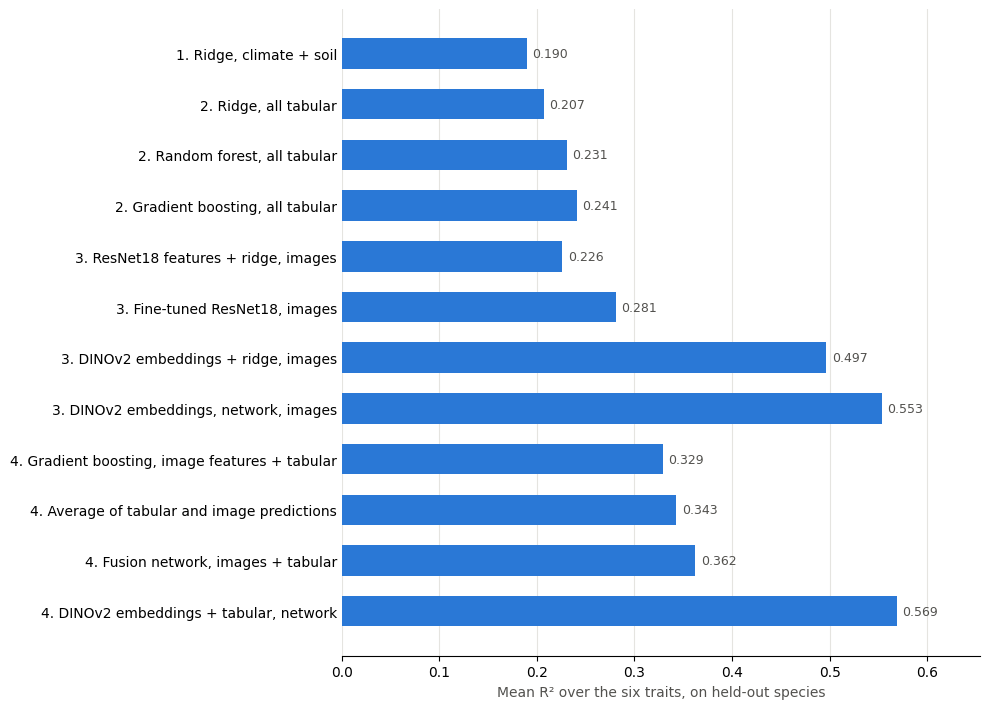

In [29]:
ordered = final_results.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.5 * len(ordered) + 1.2))
bars = ax.barh(ordered.index, ordered["test R²"], height=0.6, color="#2a78d6")
ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9, color="#52514e")
ax.set_xlabel("Mean R² over the six traits, on held-out species", color="#52514e")
ax.set_xlim(0, ordered["test R²"].max() * 1.15)
ax.xaxis.grid(True, color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

**Answers**

- **Best solution:** the small network on the DINOv2 embeddings and the tabular data, with a mean R² of 0.569 on held-out species, and a typical error of a factor of about 1.7. The pretrained foundation model provides much better descriptions of the photographs than what we can learn from this dataset alone, and the environmental data adds a little information about where the plant grows. Among the models trained on the photographs here, the fusion network is the best (0.362). Plant height is the easiest trait for every image-based model (0.755 with DINOv2 and tabular data), as it can partly be seen in the photograph, and leaf nitrogen is the hardest (0.392).
- **Issues with the dataset:**
  - The targets are species-level averages from TRY, and not measurements of the photographed plant. A seedling and an adult of the same species have the same plant height, which limits the score any model can reach.
  - Many species have very few photographs (median of 2).
  - Some target values are physically impossible.
  - The photographs vary a lot, from a whole tree to a single flower, and have no size reference.
  - Citizen science data is unevenly distributed across regions and species.
- **Possible improvements:** collect photographs paired with trait measurements of the same individual plants, filter targets with expert-defined plausible ranges, add a size reference or the plant part shown, and use the `X*_sd` columns to give less weight to uncertain targets.